In [18]:
pip install --upgrade threadpoolctl

  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 2.2.0
    Uninstalling threadpoolctl-2.2.0:
      Successfully uninstalled threadpoolctl-2.2.0
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


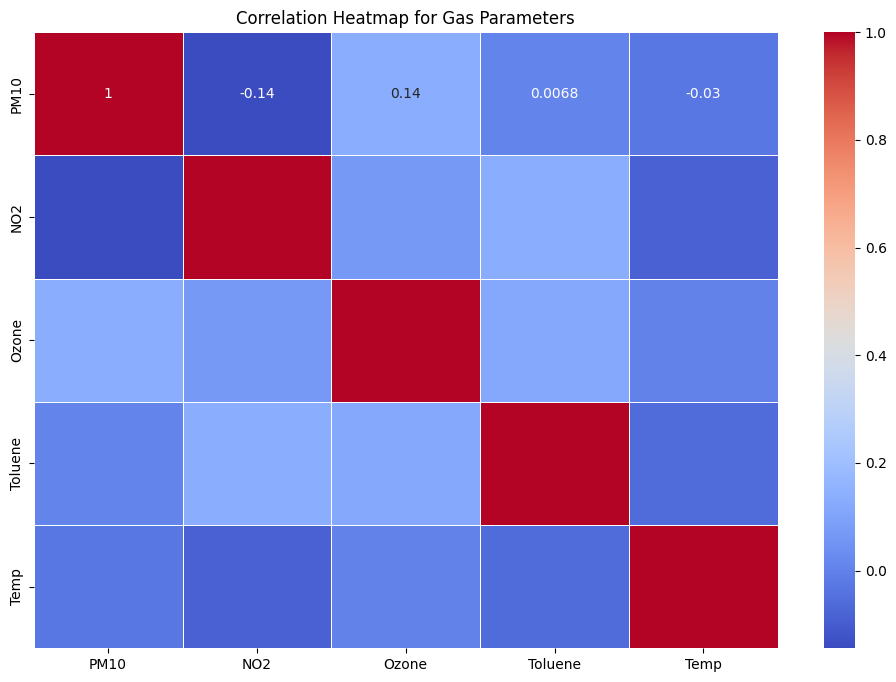

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
aqi = pd.read_excel('bollaram.xlsx')
gases_columns = ['PM10', 'NO2', 'Ozone','Toluene','Temp']
gases_data = aqi[gases_columns]
gases_data = gases_data.apply(pd.to_numeric, errors='coerce')
correlation_matrix = gases_data.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap for Gas Parameters")
plt.show()


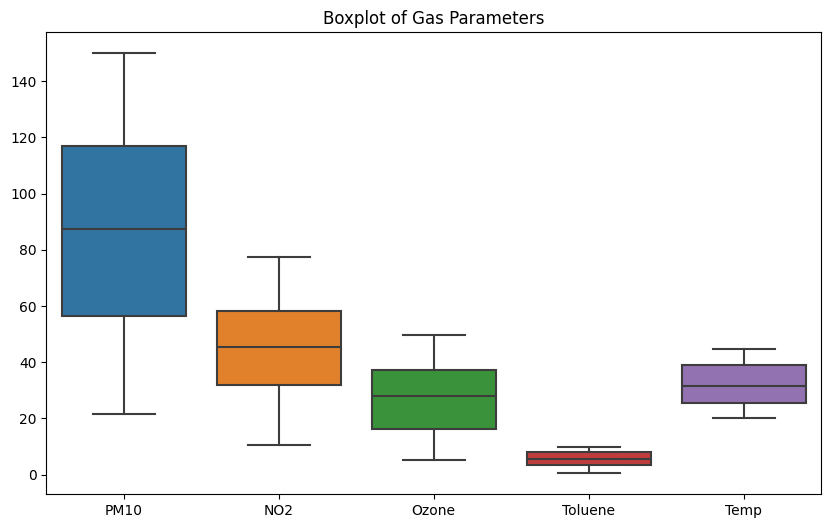

In [20]:
plt.figure(figsize=(10,6))
sns.boxplot(data=gases_data)
plt.title("Boxplot of Gas Parameters")
plt.show()

C:\Users\kathu\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\kathu\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\kathu\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\kathu\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

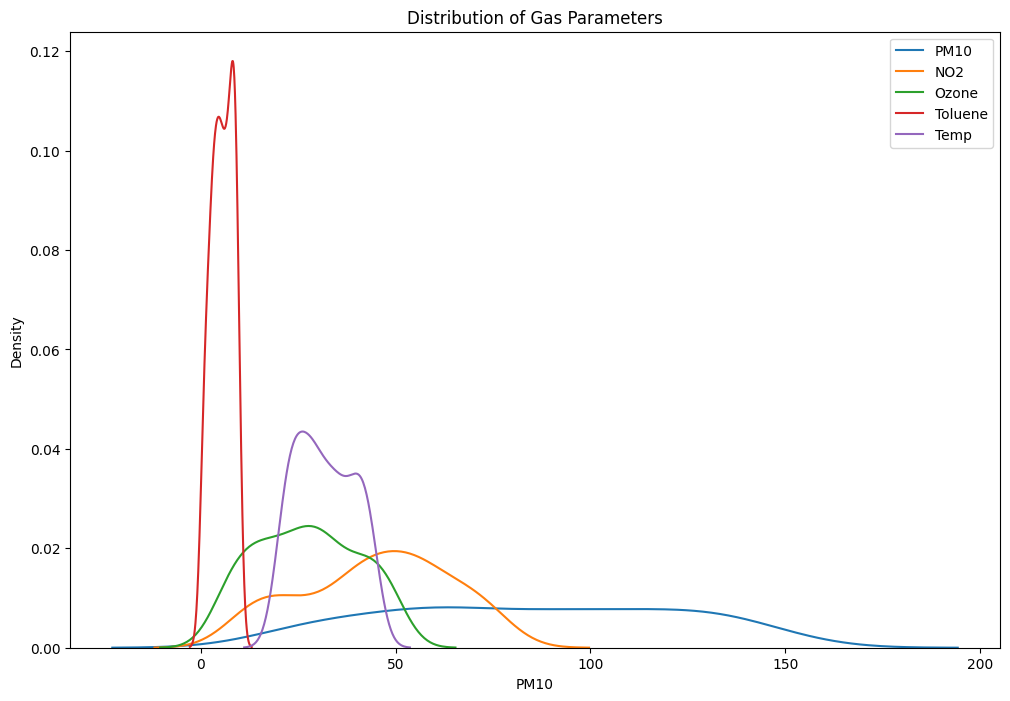

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
for col in gases_columns:
    sns.kdeplot(gases_data[col], label=col)

plt.legend()
plt.title("Distribution of Gas Parameters")
plt.show()

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd

# Fill any NaN values with the median before scaling
gases_data_clean = gases_data.fillna(gases_data.median())

# Scale the data
scaler = StandardScaler()
gases_scaled = pd.DataFrame(scaler.fit_transform(gases_data_clean), columns=gases_data.columns)

# Perform PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(gases_scaled)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)

Explained Variance Ratio: [0.25031453 0.23319855]


In [23]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
gases_data['Cluster'] = kmeans.fit_predict(gases_scaled)

sns.scatterplot(
    x=gases_scaled['PM10'],
    y=gases_scaled['NO2'],
    hue=gases_data['Cluster']
)
plt.show()

C:\Users\kathu\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


AttributeError: 'NoneType' object has no attribute 'split'

In [24]:
pca_full = PCA()
pca_full.fit(gases_scaled)

import matplotlib.pyplot as plt
plt.plot(np.cumsum(pca_full.explained_variance_ratio_))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()

NameError: name 'np' is not defined